# Experimento 1: Extrapolación de longitud en memoria asociativa
## RoPE frente a embeddings posicionales absolutos aprendidos

--- 

### **Mecanismos de Posición en minigpt**

El modelo base de `minigpt` es un decodificador transformer causal que puede gestionar la posición de los tokens de dos maneras:

* **Posiciones Aprendidas** (con el parametro *positional="learned"*): Suma un embedding posicional absoluto entrenable directamente al embedding del token:

$$
x_i = \operatorname{tok\_emb}(t_i) + \operatorname{pos\_emb}(i),
\qquad \operatorname{pos\_emb}\in\mathbb{R}^{L_{\text{ctx}}\times d}.
$$

El principal problema que se encuentra con esta configuración es que la suma es estática de forma que el embedding posicional solo se entrena en las posiciones vistas. Al evaluar secuencias más largas, las posiciones nuevas conservan su ruido aleatorio inicial ($N(0,0.02)$), lo que degrada drásticamente la predicción.

* **Posiciones Relativas** (con el parámetro *positional="rope"*): Elimina la tabla estática e inyecta la posición rotando matemáticamente las Consultas ($q$) y Claves ($k$) en la capa de atención:
$$
q_m = R(\Theta_m)q,\qquad k_n = R(\Theta_n)k, \qquad q_m^\top k_n = q^\top R(\Theta_{n-m})k
$$
Al utilizar el producto anterior, la información posicional que se añade depende exclusivamente de la diferencia relativa entre tokens ($n-m$). De esta forma se consigue evitar posiciones "sin entrenar" y otorga invariancia espacial.

### **Tarea de Evaluación: Memoria Asociativa**

Cone el fin de evaluar el correcto funcionamiento de la implementación de RoPE, así como comprobar la mejora ante secuencias de longitud mayor a las observadas durante el entrenamiento, se propone la siguiente tarea a realizar: el modelo deberá leer secuencias de pares clave-valor (claves A–Z, valores 0–9) y debe recuperar el valor de una clave consultada. 

**Ejemplo del formato:**
`G: 4, T: 7, A: 2, Z: 9 QUERY A 2 <|endoftext|>`

* **Diseño deliberado:** El valor objetivo (2) se sitúa **inmediatamente después** de la clave consultada (A), utilizando el token especial `<|endoftext|>` exclusivamente como terminador de secuencia.
* **Justificación:** Este formato permite que las cabezas de inducción copien el token contiguo. En pruebas preliminares se observó que si se interponen separadores entre la consulta y el valor (ej. `QUERY A: 2`), los modelos pequeños no logran aprender la recuperación en múltiples saltos.

### **Hipótesis del Experimento**

* **H1:** Ambos modelos (`learned` y `rope`) superarán el 95% de precisión validando con secuencias cortas vistas durante el entrenamiento (4–6 pares).
* **H2:** El modelo `learned` colapsará al extrapolar texto más largo debido a que sus embeddings posicionales no vistos actúan como ruido aleatorio.
* **H3:** El modelo con RoPE mantendrá una alta precisión en longitudes de contexto no vistas gracias a la invariancia relativa de sus rotaciones trigonométricas.
* **H4:** RoPE demuestra ser numéricamente invariante a la traslación espacial, mientras que la codificación estática no lo es.

## 1 - Configuración del entorno y carga de artefactos

Se cargan los conjuntos sintéticos, los historiales de entrenamiento y los
pesos guardados por `scripts/entrenamiento_exp1.py`. El vocabulario compacto se obtiene
del tokenizador BPE de GPT-2 (`tiktoken`) restringido a los 42 tokens de la
tarea, más un token de relleno.


In [1]:
import json
import warnings

warnings.filterwarnings("ignore", message=".*IProgress not found.*")
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "data" / "dataset_asociativo.py").is_file():
    EXPERIMENT_DIR = NOTEBOOK_DIR
elif (NOTEBOOK_DIR / "experimento1_asociativo" / "data" / "dataset_asociativo.py").is_file():
    EXPERIMENT_DIR = NOTEBOOK_DIR / "experimento1_asociativo"
elif NOTEBOOK_DIR.name == "notebooks":
    EXPERIMENT_DIR = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError("No se encontró el directorio del experimento 1")
PROJECT_ROOT = EXPERIMENT_DIR.parent
for path in (EXPERIMENT_DIR, EXPERIMENT_DIR / "data", EXPERIMENT_DIR / "scripts", PROJECT_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import dataset_asociativo as data
import entrenamiento_exp1 as training
from minigpt.experiments import translation_invariance_error

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
COLORS = {"learned": "#d1495b", "rope": "#1f77b4"}
LABELS = {"learned": "Learned (pos. absolutas)", "rope": "RoPE (pos. relativas)"}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with (EXPERIMENT_DIR / "resultados_experimento1.json").open(encoding="utf-8") as handle:
    results = json.load(handle)
with (data.DATA_DIR / "metadata.json").open(encoding="utf-8") as handle:
    metadata = json.load(handle)

train = data.load_examples(data.DATA_DIR / "train.json")
val = data.load_examples(data.DATA_DIR / "val.json")
tests = {
    n_pairs: data.load_examples(data.DATA_DIR / f"test_pairs_{n_pairs}.json")
    for n_pairs in data.TEST_PAIR_LENGTHS
}
tokenizer = data.AssociativeTokenizer()

print("Dispositivo:", DEVICE)
print(f"Vocabulario compacto: {tokenizer.vocab_size} tokens (42 de tarea + <pad>)")
print("Tokens:", tokenizer.id_to_token)

Dispositivo: cuda
Vocabulario compacto: 43 tokens (42 de tarea + <pad>)
Tokens: [',', ':', ' ', ' T', ' S', ' I', ' A', ' C', ' M', ' B', ' P', ' 1', ' D', ' 2', ' H', ' W', ' R', ' F', ' N', ' G', ' L', ' E', ' O', ' J', ' U', ' K', ' 3', ' V', ' Y', ' 4', ' 5', ' 0', ' 6', ' 7', ' 8', ' 9', ' Z', ' Q', ' X', ' QU', 'ERY', '<|endoftext|>', '<pad>']


## 2 - Generación y exploración del dataset

Particiones usadas:

| Conjunto | Pares por secuencia | Ejemplos | Longitud en tokens |
|---|---|---:|---:|
| Entrenamiento | 4–6 | 10 000 | 21–29 |
| Validación in-distribution | 4–6 | 1 000 | 21–29 |
| Test de extrapolación | 6, 8, 12, 16, 20, 24 | 1 000 por longitud | 29, 37, 53, 69, 85, 101 |

La longitud en tokens sigue $4n+5$ para $n$ pares: cada par aporta clave, `:`, valor y coma (salvo el último), y la consulta aporta `QUERY`, clave, valor, un espacio y el terminador `<|endoftext|>`.


,conjunto,ejemplos,pares mín.,pares máx.,tokens mín.,tokens máx.,tokens medios
0,train,10000,4,6,21,29,24.98
1,validación,1000,4,6,21,29,25.10
2,test 6 pares,1000,6,6,29,29,29.00
3,test 8 pares,1000,8,8,37,37,37.00
4,test 12 pares,1000,12,12,53,53,53.00
5,test 16 pares,1000,16,16,69,69,69.00
6,test 20 pares,1000,20,20,85,85,85.00
7,test 24 pares,1000,24,24,101,101,101.00


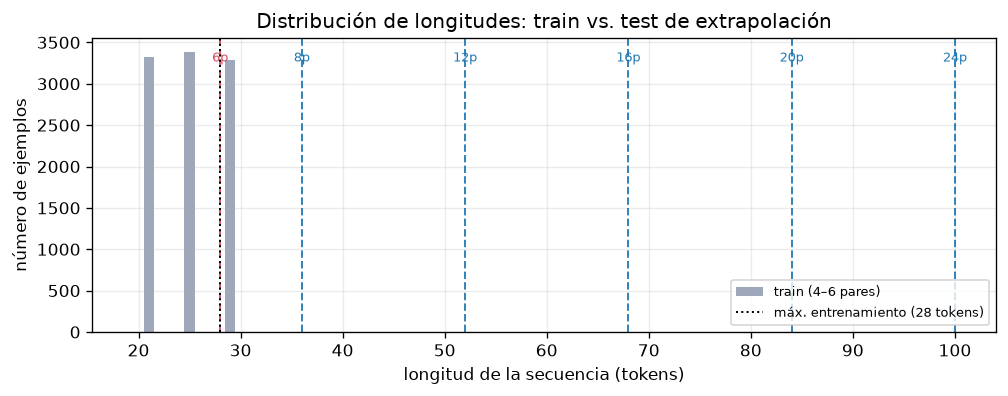

In [2]:
rows = []
for name, examples in (
    [("train", train), ("validación", val)]
    + [(f"test {n} pares", tests[n]) for n in data.TEST_PAIR_LENGTHS]
):
    stats = data.dataset_statistics(examples)
    rows.append({
        "conjunto": name,
        "ejemplos": int(stats["n_examples"]),
        "pares mín.": int(stats["min_pairs"]),
        "pares máx.": int(stats["max_pairs"]),
        "tokens mín.": int(stats["min_tokens"]),
        "tokens máx.": int(stats["max_tokens"]),
        "tokens medios": round(stats["mean_tokens"], 2),
    })
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
train_lengths = [len(example.token_ids) for example in train]
test_lengths = [4 * n + 4 for n in data.TEST_PAIR_LENGTHS]
ax.hist(train_lengths, bins=np.arange(19.5, 30.5, 1), color="#8d99ae",
        alpha=0.85, label="train (4–6 pares)")
for n_pairs, length in zip(data.TEST_PAIR_LENGTHS, test_lengths):
    ax.axvline(length, color=COLORS["rope"] if n_pairs > 6 else COLORS["learned"],
               ls="--", linewidth=1.2, alpha=0.9)
    ax.text(length, ax.get_ylim()[1] * 0.92, f"{n_pairs}p", ha="center",
            fontsize=8, color=COLORS["rope"] if n_pairs > 6 else COLORS["learned"])
ax.axvline(28, color="black", ls=":", linewidth=1.2, label="máx. entrenamiento (28 tokens)")
ax.set_xlabel("longitud de la secuencia (tokens)")
ax.set_ylabel("número de ejemplos")
ax.set_title("Distribución de longitudes: train vs. test de extrapolación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 2.1 Formato exacto y posición de la respuesta

La respuesta es el antepenúltimo token (después hay un espacio y el terminador `<|endoftext|>`). Por tanto, `answer_position = len(token_ids) - 3`. El modelo predice ese token con el logit de la posición anterior, que coincide con la clave de la consulta. Así, la cabeza de inducción solo necesita copiar el token que siguió a la aparición previa de esa misma clave.


In [3]:
print("Ejemplos de entrenamiento (4–6 pares):")
for example in train[:2]:
    print(" texto :", example.text)
    print(" tokens:", [tokenizer.id_to_token[i] for i in example.token_ids])
    print(f" respuesta: {tokenizer.id_to_token[example.token_ids[example.answer_position]]!r} "
          f"en la posición {example.answer_position} (antepenúltima); "
          f"terminador final: {tokenizer.id_to_token[example.token_ids[-1]]!r}")
    print()

print("Ejemplo de extrapolación (24 pares, 101 tokens):")
example = tests[24][0]
print(" texto :", example.text)
print(" tokens:", [tokenizer.id_to_token[i] for i in example.token_ids])
print(f" respuesta: {tokenizer.id_to_token[example.token_ids[example.answer_position]]!r} "
      f"en la posición {example.answer_position}; terminador final: "
      f"{tokenizer.id_to_token[example.token_ids[-1]]!r}")
print(f" longitud total: {len(example.token_ids)} tokens")


Ejemplos de entrenamiento (4–6 pares):
 texto :  K: 3, Q: 9, U: 9, D: 8 QUERY D 8 <|endoftext|>
 tokens: [' K', ':', ' 3', ',', ' Q', ':', ' 9', ',', ' U', ':', ' 9', ',', ' D', ':', ' 8', ' QU', 'ERY', ' D', ' 8', ' ', '<|endoftext|>']
 respuesta: ' 8' en la posición 18 (antepenúltima); terminador final: '<|endoftext|>'

 texto :  R: 0, X: 9, P: 1, S: 1, O: 4, H: 1 QUERY S 1 <|endoftext|>
 tokens: [' R', ':', ' 0', ',', ' X', ':', ' 9', ',', ' P', ':', ' 1', ',', ' S', ':', ' 1', ',', ' O', ':', ' 4', ',', ' H', ':', ' 1', ' QU', 'ERY', ' S', ' 1', ' ', '<|endoftext|>']
 respuesta: ' 1' en la posición 26 (antepenúltima); terminador final: '<|endoftext|>'

Ejemplo de extrapolación (24 pares, 101 tokens):
 texto :  W: 1, L: 5, G: 4, F: 4, M: 0, N: 8, K: 6, V: 7, T: 3, Q: 0, I: 4, X: 5, Z: 2, A: 1, H: 0, E: 8, Y: 3, O: 8, P: 8, J: 1, R: 0, U: 8, S: 5, C: 0 QUERY V 7 <|endoftext|>
 tokens: [' W', ':', ' 1', ',', ' L', ':', ' 5', ',', ' G', ':', ' 4', ',', ' F', ':', ' 4', ',', ' M', ':', 

## 3 - Configuración y entrenamiento

Ambos modelos comparten arquitectura, inicialización y datos; la **única** diferencia es el esquema posicional. La comprobación de inicialización común del script encontró 72 tensores comunes con diferencia máxima exactamente $0$. El modelo `learned` añade la tabla `pos_emb` (256 × 128 = 32 768 parámetros); RoPE no tiene parámetros posicionales.

El entrenamiento usa AdamW ($\text{lr}=10^{-3}$, *weight decay* $0.01$), calentamiento de 100 pasos, decaimiento coseno, lote de 64 y pérdida deentropía cruzada solo en el token de respuesta. Se ejecutaron 4 000 pasos por modelo.


,variante,positional,vocab_size,context_length,emb_dim,n_heads,n_layers,params posicionales,parámetros totales
0,Learned (pos. absolutas),learned,43,256,128,4,4,32768,837120
1,RoPE (pos. relativas),rope,43,256,128,4,4,0,804352


Checkpoints cargados:
  Learned (pos. absolutas)     /home/usuario/A4/PL/Practica1_PLN1/experimento1_asociativo/pesos/learned/best_model.pt  (4.4 MB)
  RoPE (pos. relativas)        /home/usuario/A4/PL/Practica1_PLN1/experimento1_asociativo/pesos/rope/best_model.pt  (4.3 MB)


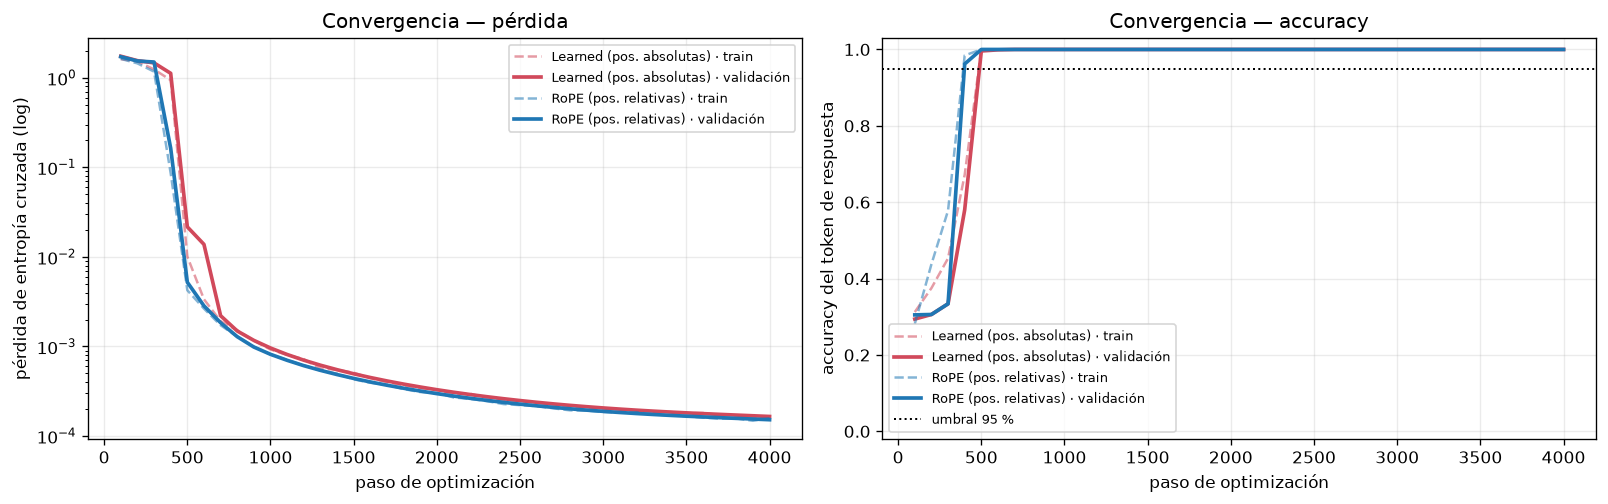

Resumen de entrenamiento:
  Learned (pos. absolutas)     mejor paso=4000  val_loss=0.000165  val_acc=100.00%  tiempo=85.3 s
  RoPE (pos. relativas)        mejor paso=4000  val_loss=0.000152  val_acc=100.00%  tiempo=90.1 s


In [4]:
checkpoints = {}
for positional in ("learned", "rope"):
    path = data.WEIGHTS_ROOT / positional / "best_model.pt"
    model, history, payload = training.load_checkpoint(path, device=DEVICE)
    checkpoints[positional] = {
        "model": model,
        "history": history,
        "payload": payload,
        "path": path,
    }

config_rows = []
for positional, info in checkpoints.items():
    cfg = info["model"].cfg
    config_rows.append({
        "variante": LABELS[positional],
        "positional": cfg.positional,
        "vocab_size": cfg.vocab_size,
        "context_length": cfg.context_length,
        "emb_dim": cfg.emb_dim,
        "n_heads": cfg.n_heads,
        "n_layers": cfg.n_layers,
        "params posicionales": info["model"].positional_parameters,
        "parámetros totales": sum(p.numel() for p in info["model"].parameters()),
    })
display(pd.DataFrame(config_rows))

print("Checkpoints cargados:")
for positional, info in checkpoints.items():
    size_mb = info["path"].stat().st_size / 1e6
    print(f"  {LABELS[positional]:<28} {info['path']}  ({size_mb:.1f} MB)")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
for positional, info in checkpoints.items():
    history = info["history"]
    axes[0].plot(history.steps, history.train_losses, "--",
                 color=COLORS[positional], alpha=0.55,
                 label=f"{LABELS[positional]} · train")
    axes[0].plot(history.val_steps, history.val_losses, "-",
                 color=COLORS[positional], linewidth=2.2,
                 label=f"{LABELS[positional]} · validación")
    axes[1].plot(history.steps, history.train_accuracies, "--",
                 color=COLORS[positional], alpha=0.55,
                 label=f"{LABELS[positional]} · train")
    axes[1].plot(history.val_steps, history.val_accuracies, "-",
                 color=COLORS[positional], linewidth=2.2,
                 label=f"{LABELS[positional]} · validación")

axes[0].set_yscale("log")
axes[0].set_xlabel("paso de optimización")
axes[0].set_ylabel("pérdida de entropía cruzada (log)")
axes[0].set_title("Convergencia — pérdida")
axes[0].legend(fontsize=8)

axes[1].axhline(0.95, color="black", ls=":", linewidth=1.2, label="umbral 95 %")
axes[1].set_xlabel("paso de optimización")
axes[1].set_ylabel("accuracy del token de respuesta")
axes[1].set_title("Convergencia — accuracy")
axes[1].set_ylim(-0.02, 1.03)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Resumen de entrenamiento:")
for positional, info in checkpoints.items():
    history = info["history"]
    print(f"  {LABELS[positional]:<28} mejor paso={history.best_step:4d}  "
          f"val_loss={history.best_val_loss:.6f}  "
          f"val_acc={history.best_val_accuracy:.2%}  "
          f"tiempo={history.elapsed_seconds:.1f} s")


## 4 - Evaluación de extrapolación de longitud

Se evalúa el *accuracy* exacto del token de respuesta en los conjuntos de test
con longitudes crecientes. La longitud 6 está dentro del rango de
entrenamiento (4–6 pares); 8, 12, 16, 20 y 24 son longitudes no vistas.


In [5]:
length_rows = []
for n_pairs in data.TEST_PAIR_LENGTHS:
    row = {"pares": n_pairs, "tokens": 4 * n_pairs + 5}
    for positional, info in checkpoints.items():
        metrics = training.evaluate_recall(
            info["model"], tests[n_pairs], tokenizer, device=DEVICE
        )
        row[f"{positional}_acc"] = metrics["accuracy"]
        row[f"{positional}_loss"] = metrics["loss"]
    length_rows.append(row)
df_length = pd.DataFrame(length_rows)

view = pd.DataFrame({
    "Pares": df_length["pares"],
    "Tokens": df_length["tokens"],
    "Learned acc": df_length["learned_acc"].map(lambda x: f"{x:.2%}"),
    "RoPE acc": df_length["rope_acc"].map(lambda x: f"{x:.2%}"),
    "Δ (RoPE − Learned)": (df_length["rope_acc"] - df_length["learned_acc"]).map(
        lambda x: f"{x:+.2%}"
    ),
    "Learned loss": df_length["learned_loss"].map(lambda x: f"{x:.4f}"),
    "RoPE loss": df_length["rope_loss"].map(lambda x: f"{x:.4f}"),
})
display(view)

saved = results["evaluations"]
max_diff = max(
    abs(df_length.loc[i, f"{positional}_acc"]
        - saved[positional]["by_length"][str(n_pairs)]["accuracy"])
    for i, n_pairs in enumerate(data.TEST_PAIR_LENGTHS)
    for positional in ("learned", "rope")
)
print(f"Verificación frente a los resultados guardados: "
      f"diferencia máxima de accuracy = {max_diff:.2e}")

print("Validación in-distribution (4–6 pares):")
for positional, info in checkpoints.items():
    metrics = training.evaluate_recall(info["model"], val, tokenizer, device=DEVICE)
    print(f"  {LABELS[positional]:<28} loss={metrics['loss']:.6f}  "
          f"accuracy={metrics['accuracy']:.2%}")


,Pares,Tokens,Learned acc,RoPE acc,Δ (RoPE − Learned),Learned loss,RoPE loss
0,6,29,100.00%,100.00%,+0.00%,0.0002,0.0002
1,8,37,73.90%,100.00%,+26.10%,1.8268,0.0002
2,12,53,47.70%,98.40%,+50.70%,3.8437,0.0804
3,16,69,41.40%,96.30%,+54.90%,4.4007,0.1910
4,20,85,36.40%,90.40%,+54.00%,4.8257,0.5222
5,24,101,30.10%,82.30%,+52.20%,5.0945,1.1134


Verificación frente a los resultados guardados: diferencia máxima de accuracy = 0.00e+00
Validación in-distribution (4–6 pares):
  Learned (pos. absolutas)     loss=0.000165  accuracy=100.00%


  RoPE (pos. relativas)        loss=0.000152  accuracy=100.00%


## 5 -Visualización de resultados

La figura principal compara el *accuracy* y la pérdida en función de la
longitud. La zona sombreada corresponde a longitudes no vistas durante el
entrenamiento.


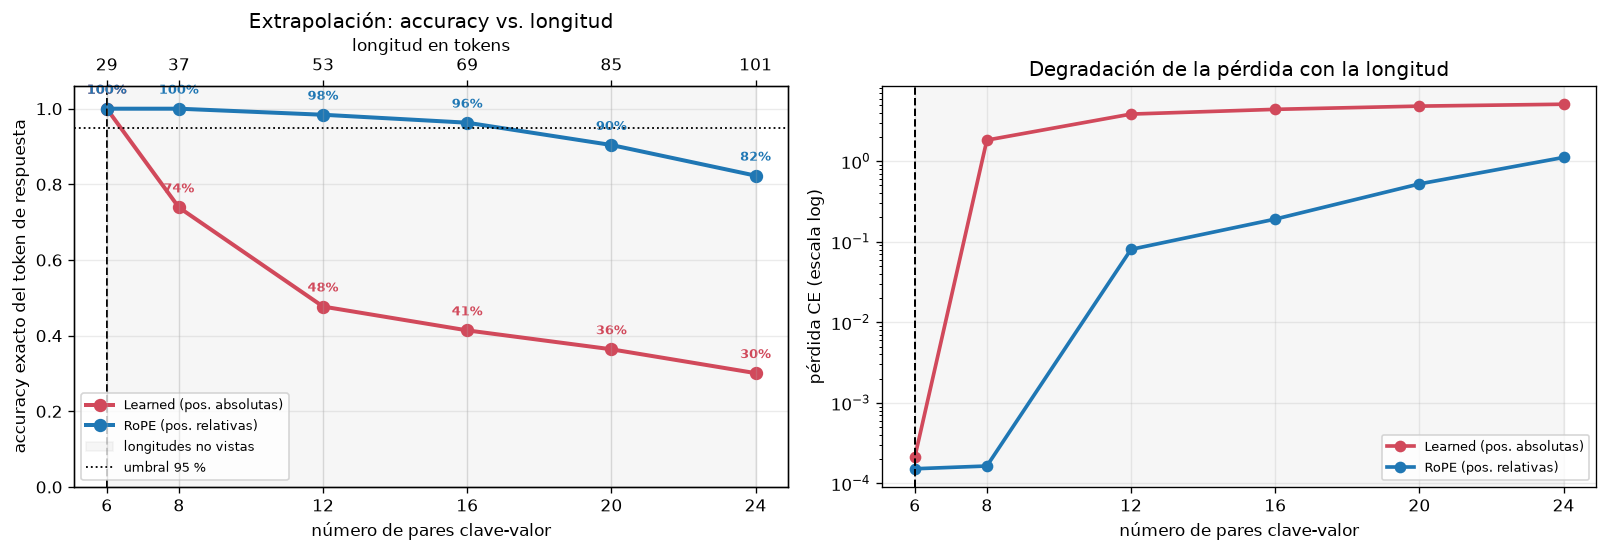

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))

ax = axes[0]
for positional in ("learned", "rope"):
    ax.plot(df_length["pares"], df_length[f"{positional}_acc"],
            marker="o", linewidth=2.4, markersize=7,
            color=COLORS[positional], label=LABELS[positional])
    for x, y in zip(df_length["pares"], df_length[f"{positional}_acc"]):
        ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8,
                    color=COLORS[positional], fontweight="bold")
ax.axvline(6, color="black", ls="--", linewidth=1.2)
ax.axvspan(6, 24, color="gray", alpha=0.07, label="longitudes no vistas")
ax.axhline(0.95, color="black", ls=":", linewidth=1.1, label="umbral 95 %")
ax.set_xlabel("número de pares clave-valor")
ax.set_ylabel("accuracy exacto del token de respuesta")
ax.set_title("Extrapolación: accuracy vs. longitud")
ax.set_xticks(df_length["pares"])
ax.set_ylim(0.0, 1.06)
ax.legend(loc="lower left", fontsize=8)
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(df_length["pares"])
ax_top.set_xticklabels(df_length["tokens"])
ax_top.set_xlabel("longitud en tokens")

ax = axes[1]
for positional in ("learned", "rope"):
    ax.plot(df_length["pares"], df_length[f"{positional}_loss"],
            marker="o", linewidth=2.2, color=COLORS[positional],
            label=LABELS[positional])
ax.set_yscale("log")
ax.set_xlabel("número de pares clave-valor")
ax.set_ylabel("pérdida CE (escala log)")
ax.set_title("Degradación de la pérdida con la longitud")
ax.set_xticks(df_length["pares"])
ax.axvline(6, color="black", ls="--", linewidth=1.2)
ax.axvspan(6, 24, color="gray", alpha=0.07)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('images/extrapolacion_acc.pdf', bbox_inches='tight')
plt.show()


### 5.1 Diagnóstico: filas de `pos_emb` e invariancia a traslación

El modelo `learned` solo usó posiciones 0–28 durante el entrenamiento (29 tokens como máximo). Las filas 29–255 de `pos_emb` no recibieron gradiente y conservan la inicialización $N(0,0.02)$: su norma media es claramente menor que la de las filas entrenadas. Además, al desplazar la ventana de posiciones, RoPE debe dejar los logits prácticamente intactos, mientras que `learned` no.

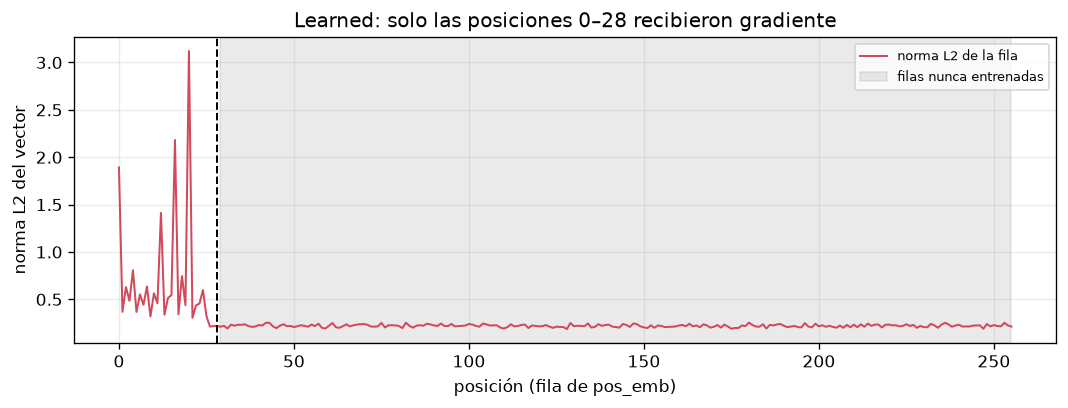

Posiciones entrenadas: 0..28 (29 filas)
Posiciones sin entrenar: 29..255 (227 filas)
Norma media de las filas entrenadas   : 0.6873
Norma media de las filas sin entrenar : 0.2210

Error máximo de logits al desplazar la ventana 10 posiciones (misma secuencia, mismas claves/valores):
  Learned (pos. absolutas)     error = 8.946e+00
  RoPE (pos. relativas)        error = 8.583e-06


In [7]:
learned_model = checkpoints["learned"]["model"]
wpe_norms = learned_model.pos_emb.weight.detach().cpu().norm(dim=1).numpy()
max_train_tokens = 4 * data.TRAIN_PAIRS[1] + 5  # 29

fig, ax = plt.subplots(figsize=(9.0, 3.5))
ax.plot(wpe_norms, color=COLORS["learned"], linewidth=1.2,
        label="norma L2 de la fila")
ax.axvspan(max_train_tokens, len(wpe_norms) - 1, color="gray", alpha=0.16,
           label="filas nunca entrenadas")
ax.axvline(max_train_tokens - 1, color="black", ls="--", linewidth=1.2)
ax.set_xlabel("posición (fila de pos_emb)")
ax.set_ylabel("norma L2 del vector")
ax.set_title(f"Learned: solo las posiciones 0–{max_train_tokens - 1} recibieron gradiente")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Posiciones entrenadas: 0..{max_train_tokens - 1} "
      f"({max_train_tokens} filas)")
print(f"Posiciones sin entrenar: {max_train_tokens}.."
      f"{learned_model.cfg.context_length - 1} "
      f"({learned_model.cfg.context_length - max_train_tokens} filas)")
print(f"Norma media de las filas entrenadas   : "
      f"{wpe_norms[:max_train_tokens].mean():.4f}")
print(f"Norma media de las filas sin entrenar : "
      f"{wpe_norms[max_train_tokens:].mean():.4f}")

sample_inputs, _, _ = data.collate_examples(
    val[:8], tokenizer.pad_id, device=DEVICE
)
offset = 10
print(f"\nError máximo de logits al desplazar la ventana {offset} posiciones "
      f"(misma secuencia, mismas claves/valores):")
for positional, info in checkpoints.items():
    error = translation_invariance_error(info["model"], sample_inputs, offset=offset)
    print(f"  {LABELS[positional]:<28} error = {error:.3e}")


## 6 - Análisis y conclusiones del Experimento 1 (Associative Recall)

### Resultados principales

| Fenómeno | Observación |
|---|---|
| Aprendizaje en secuencias cortas (vistas en entrenamiento) | Ambos modelos (RoPE y Posiciones Estáticas) alcanzan un **100% de precisión** (4-6 pares). |
| Extrapolación a 8 pares | El modelo con posiciones estáticas (`learned`) decae al **73,9%**; la variante RoPE mantiene el **100%**. |
| Extrapolación a secuencias largas (24 pares, 4x la longitud de entrenamiento) | El modelo `learned` colapsa al **30,1%**; RoPE conserva un **82,3%** de precisión. |
| Invariancia a la traslación espacial | El modelo `learned` sufre variaciones notables en sus predicciones (error logits ≈ **8,95**); RoPE es matemáticamente inalterable ante el desplazamiento (error mínimo de cálculo de **8,6·10⁻⁶**). |
| Carga en memoria por parámetros espaciales | El modelo `learned` requiere almacenar una matriz de **32 768 parámetros**; RoPE no requiere **ningún parámetro adicional** (0). |

### Interpretación de Hipótesis

1. **H1 (Capacidad Base):** Ambos modelos logran asimilar perfectamente la tarea con secuencias cortas. Esto se logra colocando el valor objetivo directamente tras la clave, permitiendo que la cabeza de inducción copie el token exitosamente (las pruebas mostraron que insertar separadores como `:` entre medias bloqueaba el aprendizaje en modelos pequeños).
2. **H2 (Colapso del Modelo Estático):** La matriz posicional del modelo `learned` solo recibe gradientes en las posiciones iniciales (las únicas que ve entrenando). Al extender el texto a 24 pares, las posiciones nuevas heredan la inicialización aleatoria de la matriz ($N(0,0.02)$), actuando como puro ruido que destruye la precisión del modelo.
3. **H3 (Robustez de RoPE en extrapolación):** RoPE elimina esa matriz estática. En su lugar, aplica rotaciones matemáticas sobre Consultas y Claves (`apply_rotary`). Esto vincula la interacción entre tokens exclusivamente a su **distancia relativa**, independientemente de lo larga que sea la frase, manteniendo un rendimiento muy alto en extrapolación (82,3% en secuencias extremas).
4. **H4 (Invariancia Translacional):** Se ha demostrado numéricamente que la ecuación relativa de RoPE hace al modelo prácticamente invulnerable a desplazamientos posicionales arbitrarios.

### Limitaciones del estudio

* **Complejidad:** La tarea es un entorno sintético muy acotado ejecutado en arquitecturas deliberadamente pequeñas (4 capas, 128 dimensiones).
* **Degradación natural:** Aunque RoPE rinde infinitamente mejor que el enfoque clásico (82,3% vs 30,1%), también sufre una leve caída de rendimiento en textos muy largos. Esto sugiere que a un modelo de este tamaño le cuesta concentrar la atención cuando se enfrenta a una sobredosis de distractores en el contexto, independientemente de entender la posición espacial.

### Conclusión General
El experimento prueba empíricamente la superioridad estructural de RoPE para extrapolar longitudes de contexto. Eliminar la matriz posicional estática y delegar la inyección espacial a cálculos trigonométricos sobre Q y K permite al modelo procesar posiciones que jamás vio durante su entrenamiento sin perder el hilo de la información.

---
<small> *Reproducibilidad.* Los datos, pesos e historiales se generan con
`experimento1_asociativo/scripts/entrenamiento_exp1.py`. Las semillas son 2026 (datos),
42 (inicialización) y 123 (lotes de entrenamiento). Los pesos se guardan en
`experimento1_asociativo/pesos/{learned,rope}/best_model.pt` y los
resultados completos en `experimento1_asociativo/resultados_experimento1.json`. <small>
